<a href="https://colab.research.google.com/github/Faiva-404/PCVK_Ganjil_2026/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Faiva Puspa Sahara (06)
> MODUL P9 – Morfologi (Erosi, Dilasi, Opening, Closing,
Transformasi Top-hat dan Bottom-hat, Skeleton, Thickening)

D. TUGAS PRAKTIKUM

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

3. Buatlah fungsi dilasi serta tampilkan hasil dilasi pada citra dengan Structuring Element
Dilasi (SED) berbentuk cross 3 x 3 tanpa menggunakan library morphology dari
openCV

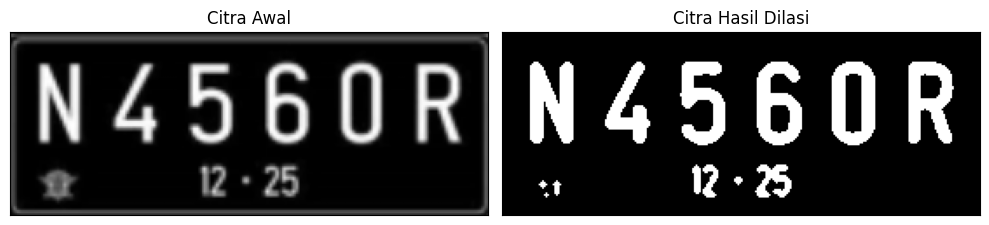

In [8]:
# Dilasi tanpa library morphology
import cv2
import numpy as np
from matplotlib import pyplot as plt

def dilasi_citra(F, w):
    # Size image
    p, q = F.shape

    # Membuat citra kosong
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate Structuring Element Dilasi (SED) Cross
    SED = np.array([
        [0, 1, 0],
        [1, 1, 1],
        [0, 1, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i - constant1:i + constant1 + 1,
                j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

# Membaca citra
img_d = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png', 0)

# Memastikan gambar berhasil dibaca
if img_d is None:
    print("Gambar tidak ditemukan. Periksa kembali lokasi dan nama file.")
else:
    # Mengubah citra menjadi biner
    ret, thresh = cv2.threshold(img_d, 125, 255, cv2.THRESH_BINARY)

    # Ukuran SED Cross 3 x 3
    w = 3
    imgD = dilasi_citra(thresh, w)

    # Menampilkan hasil
    plt.figure(figsize=(10, 4))

    plt.subplot(121)
    plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(122)
    plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi')
    plt.xticks([])
    plt.yticks([])

    plt.tight_layout()
    plt.show()

4. Buatlah program implementasi operasi dilasi Structuring Element Dilasi (SED)
berbentuk cross 3 x 3 dengan menggunakan library morphology dari openCV

[[1 1 1]
 [1 1 1]
 [1 1 1]]


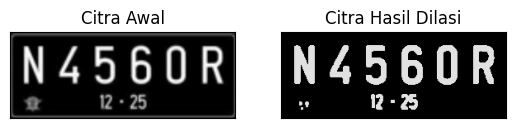

In [9]:
img = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png')
#img = cv2.imread('morp.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi = cv2.dilate(thresh,kernel,iterations = 1)
print(kernel)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

5. Buatlah fungsi erosi serta tampilkan hasil erosi pada citra dengan Structuring Element
Erosi (SE) berbentuk square 5 x 5 tanpa menggunakan library morphology dari
openCV

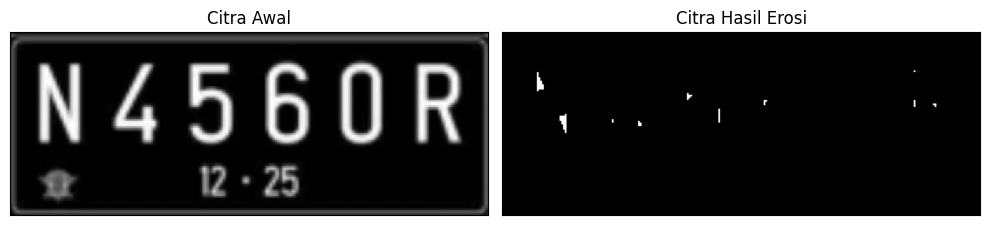

In [13]:
# Erosi Tanpa Library
def erosi_citra(F, k):
    # Size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i - constant:i + constant + 1,
                j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

# Membaca citra
img_e = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png', 0)

# Memastikan gambar berhasil dibaca
if img_e is None:
    print("Gambar tidak ditemukan. Periksa kembali lokasi dan nama file.")
else:
    ret1, thresh1 = cv2.threshold(
        img_e, 175, 225, cv2.THRESH_BINARY)
    k = 5
    imgE = erosi_citra(thresh1, k)

    # Menampilkan citra awal dan hasil erosi
    plt.figure(figsize=(10, 4))

    plt.subplot(121)
    plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(122)
    plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi')
    plt.xticks([])
    plt.yticks([])

    plt.tight_layout()
    plt.show()


6. Buatlah program implementasi operasi dilasi Structuring Element Erosi (SE) berbentuk
square 5 x 5 dengan menggunakan library morphology dari openCV

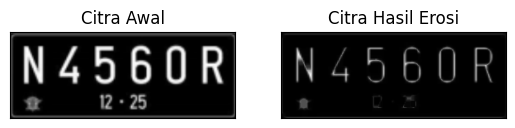

In [14]:
#EROSI LIBRARY
img = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png')
kernel = np.ones((5,5),np.uint8)
erosion = cv2.erode(img,kernel,iterations = 1)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

7. Buatlah program implementasi operasi opening dengan Structuring Element berbentuk
square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV

**Operasi Opening Menggunakan tanpa Library Morphology**

In [18]:
def dilasi_citra(F, w):
    m, n = F.shape
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2
    imgD = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant1, m - constant1):
        for j in range(constant1, n - constant1):
            temp = F[
                i-constant1:i+constant1+1,
                j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

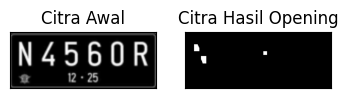

In [19]:
img_o = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png', 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()


**Operasi Opening Menggunakan Library Morphology**

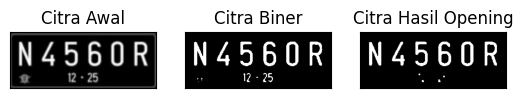

In [22]:
# Dengan Menggunakan Library
img = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png', 0)

if img is None:
    print("Gambar tidak ditemukan! Periksa lokasi dan nama file.")
else:
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint8)
    openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

    plt.subplot(131), plt.imshow(img, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

    plt.subplot(132), plt.imshow(thresh, cmap='gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])

    plt.subplot(133), plt.imshow(openn, cmap='gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

    plt.show()


8. Buatlah program implementasi operasi closing dengan Structuring Element berbentuk
square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV

**operasi closing tanpa library morphology**

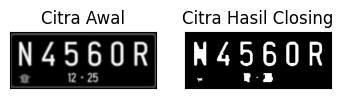

In [23]:
img_c= cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png',0) #
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k=7
imgC = erosi_citra(dilasi_citra(threshc,k),k)

plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgC,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

**operasi closing dengan library morphology**

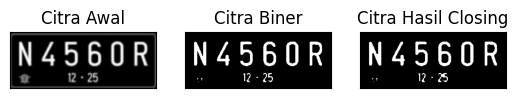

In [24]:
img = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
closs = cv2.morphologyEx(thresh,cv2.MORPH_CLOSE, kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(closs,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

9. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk
Cross 3 x 3

Cross 3


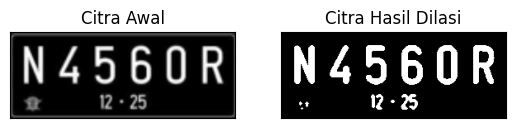

Cross 5


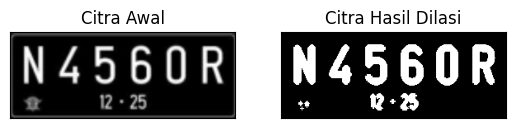

In [29]:

# Dilasi Cross SED
def dilasi_citra(F,w):
    p,q = F.shape
    imgD = np.zeros((p,q), dtype=np.uint8)

    if w == 3:
        SED = np.array([[0,1,0],[1,1,1],[0,1,0]], dtype=np.uint8)
    else:
        SED = np.array([[0,0,1,0,0],
                        [0,0,1,0,0],
                        [1,1,1,1,1],
                        [0,0,1,0,0],
                        [0,0,1,0,0]], dtype=np.uint8)

    constant1 = (w-1)//2
    for i in range(constant1,p-constant1):
        for j in range(constant1,q-constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i,j] = np.max(product)
    return imgD

img_d = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png',0)
ret, thresh = cv2.threshold(img_d,127,225,cv2.THRESH_BINARY)

# Cross 3
print('Cross 3')
imgD = dilasi_citra(thresh,3)
plt.subplot(121),plt.imshow(img_d,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])
plt.subplot(122),plt.imshow(imgD,cmap='gray')
plt.title('Citra Hasil Dilasi'),plt.xticks([]),plt.yticks([])
plt.show()

# Cross 5
print('Cross 5')
imgD = dilasi_citra(thresh,5)
plt.subplot(121),plt.imshow(img_d,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])
plt.subplot(122),plt.imshow(imgD,cmap='gray')
plt.title('Citra Hasil Dilasi'),plt.xticks([]),plt.yticks([])
plt.show()


10. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk
Circular 3 x 3 dan 5 x 5

SED = Circle 3


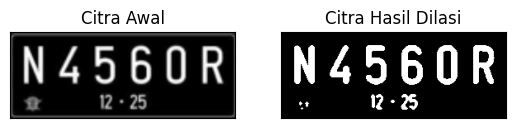

SED = Circle 5


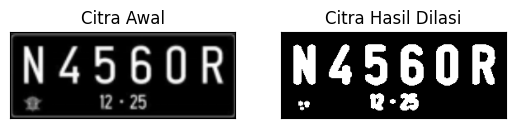

In [32]:

#Dilasi Circular SED
def dilasi_citra(F,w):
    #size image
    p,q = F.shape
    imgD = np.zeros((p,q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
    constant1 = (w-1)//2

    #Proses Dilasi
    for i in range(constant1,p-constant1):
        for j in range(constant1,q-constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i,j] = np.max(product)
    return imgD

img_d = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png',0)
ret, thresh = cv2.threshold(img_d,127,225,cv2.THRESH_BINARY)

print('SED = Circle 3')
w = 3
imgD = dilasi_citra(thresh,w)
plt.subplot(121),plt.imshow(img_d,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])
plt.subplot(122),plt.imshow(imgD,cmap='gray')
plt.title('Citra Hasil Dilasi'),plt.xticks([]),plt.yticks([])
plt.show()

print('SED = Circle 5')
w = 5
imgD = dilasi_citra(thresh,w)
plt.subplot(121),plt.imshow(img_d,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])
plt.subplot(122),plt.imshow(imgD,cmap='gray')
plt.title('Citra Hasil Dilasi'),plt.xticks([]),plt.yticks([])
plt.show()

11. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk
Rectangle 3 x 5 dan 5 x 7

SE = Line Vertikal 3


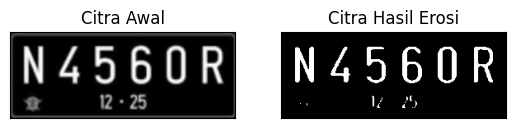

SE = Line Vertikal 5


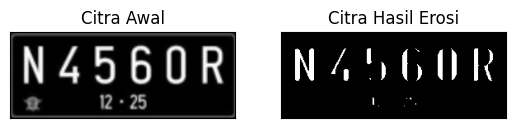

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#Erosi Line Vertikal
def erosi_citra(F,k):
    m,n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT,(1,k))
    constant = (k-1)//2
    imgE = np.zeros((m,n), dtype=np.uint8)

    for i in range(constant,m-constant):
        for j in range(constant,n-constant):
            temp = F[i-constant:i+constant+1, j:j+1]
            product = temp * SE
            imgE[i,j] = np.min(product)
    return imgE

print('SE = Line Vertikal 3')
img_e = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png',0)
ret1, thresh1 = cv2.threshold(img_e,127,225,cv2.THRESH_BINARY)
k = 3
imgE = erosi_citra(thresh1,k)

plt.subplot(121),plt.imshow(img_e,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])
plt.subplot(122),plt.imshow(imgE,cmap='gray')
plt.title('Citra Hasil Erosi'),plt.xticks([]),plt.yticks([])
plt.show()

print('SE = Line Vertikal 5')
k = 7
imgE = erosi_citra(thresh1,k)

plt.subplot(121),plt.imshow(img_e,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])
plt.subplot(122),plt.imshow(imgE,cmap='gray')
plt.title('Citra Hasil Erosi'),plt.xticks([]),plt.yticks([])
plt.show()

12. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk
Line Vertikal 3 dan 5

SE = Line Vertikal 3


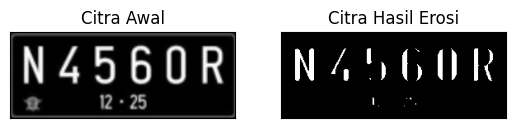

SE = Line Vertikal 5


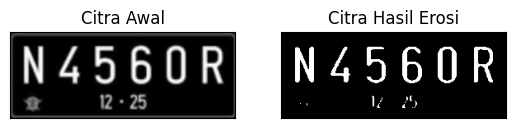

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#Erosi Line Vertikal
def erosi_citra(F,k):
    m,n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT,(1,k))
    constant = (k-1)//2
    imgE = np.zeros((m,n), dtype=np.uint8)

    for i in range(constant,m-constant):
        for j in range(constant,n-constant):
            temp = F[i-constant:i+constant+1, j:j+1]
            product = temp * SE
            imgE[i,j] = np.min(product)
    return imgE

print('SE = Line Vertikal 3')
img_e = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/Plat nomer.png',0)
ret1, thresh1 = cv2.threshold(img_e,127,225,cv2.THRESH_BINARY)
k = 7
imgE = erosi_citra(thresh1,k)

plt.subplot(121),plt.imshow(img_e,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])
plt.subplot(122),plt.imshow(imgE,cmap='gray')
plt.title('Citra Hasil Erosi'),plt.xticks([]),plt.yticks([])
plt.show()

print('SE = Line Vertikal 5')
k = 3
imgE = erosi_citra(thresh1,k)

plt.subplot(121),plt.imshow(img_e,cmap='gray')
plt.title('Citra Awal'),plt.xticks([]),plt.yticks([])
plt.subplot(122),plt.imshow(imgE,cmap='gray')
plt.title('Citra Hasil Erosi'),plt.xticks([]),plt.yticks([])
plt.show()

13. TopHat

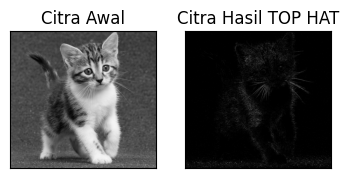

In [19]:
# Getting the kernel to be used in Top-Hat
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

14. BLACKHAT

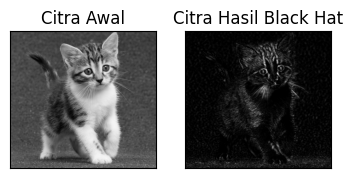

In [20]:
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
#tophat_img = cv2.morphologyEx(img,cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

15. Skeleton

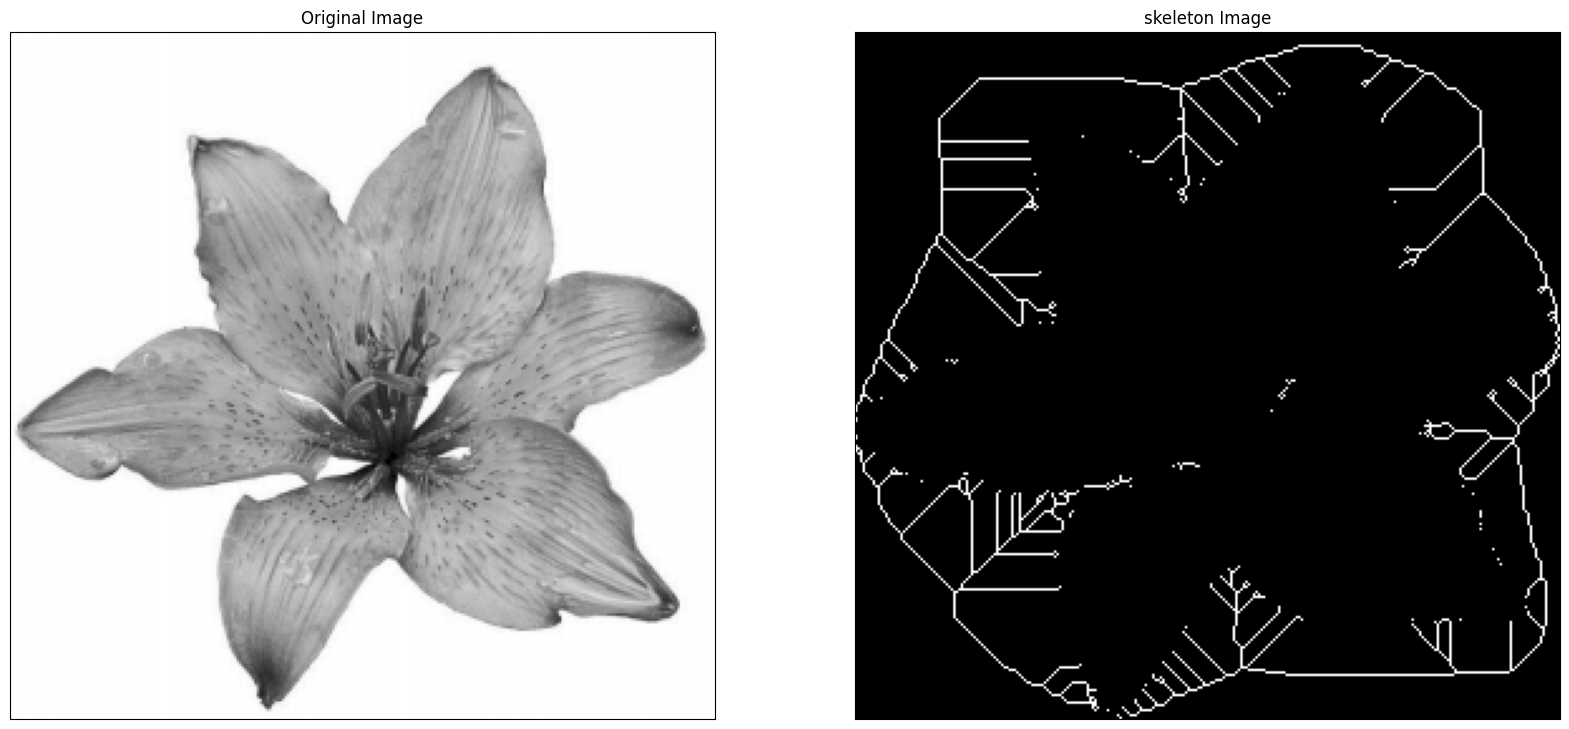

In [22]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread('/content/drive/MyDrive/SEMESTER 5/Citra/lily.png',0)
binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20,20))
plt.subplot(121),plt.imshow(img,cmap = 'gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig("binary and bin_skeleton.png")
plt.show()

16. Skeleton Inverse

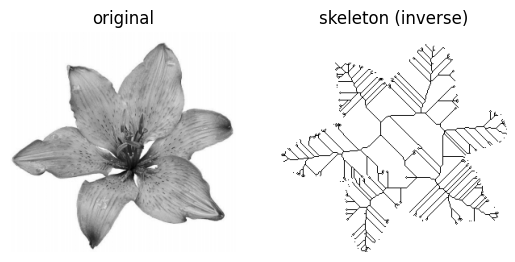

In [23]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread('/content/drive/MyDrive/SEMESTER 5/Citra/lily.png')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

17. Thickening

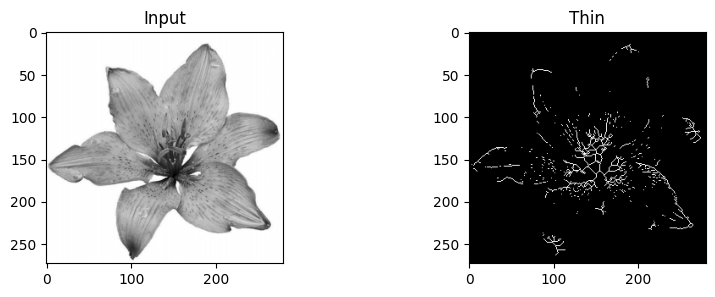

In [27]:

from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = io.imread('/content/drive/MyDrive/SEMESTER 5/Citra/lily.png')
image = img_as_float(color.rgb2gray(image[:, :, :3]))

image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()

> **E. Tugas Praktikum**


Tugas Praktikum Morfologi melibatkan implementasi dataset KTP yang terdapat dalam
Modul 7. Dalam tugas ini, kita akan menggunakan semua informasi yang disediakan dalam
modul Morfologi dan menerapkan sejumlah nilai tambahan dalam kode sumber. Tujuannya
adalah agar citra KTP dapat terbaca dengan baik ketika teknik morfologi diterapkan pada citra
tersebut.



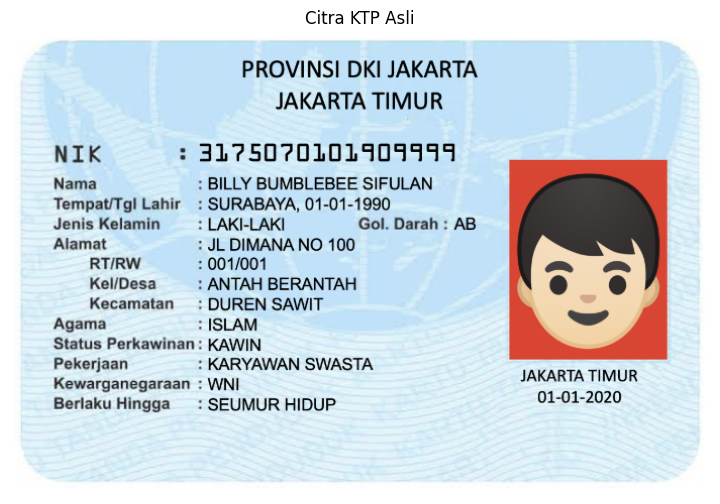

In [29]:
#Import library dan unggah citra KTP

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

img = cv2.imread('/content/drive/MyDrive/SEMESTER 5/Citra/ktp1.jpg')

if img is None:
    raise ValueError("Citra gagal dibaca. Periksa file yang diunggah.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 6))
plt.imshow(img_rgb)
plt.title("Citra KTP Asli")
plt.axis("off")
plt.show()

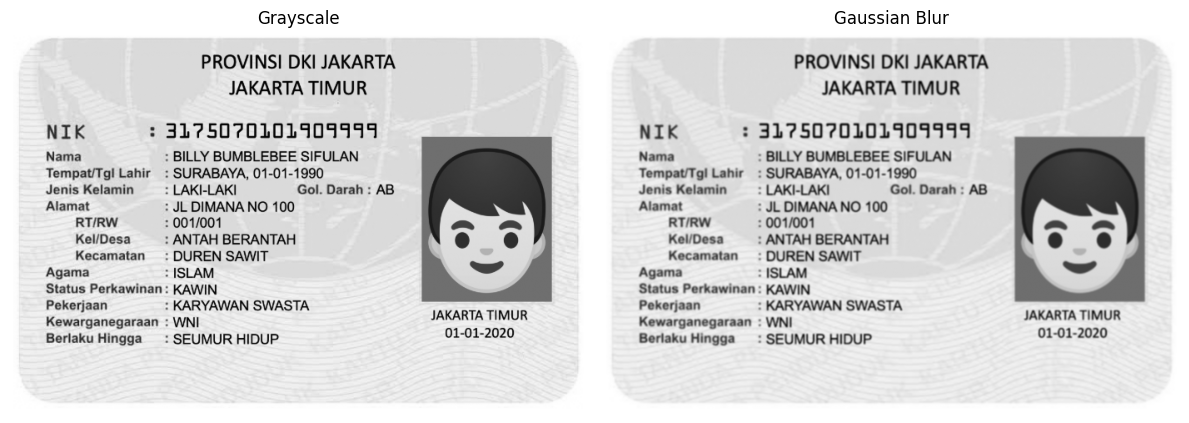

In [30]:
#Pemrosesan Citra
# Mengubah citra menjadi grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Mengurangi noise
blur = cv2.GaussianBlur(gray, (3, 3), 0)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blur, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

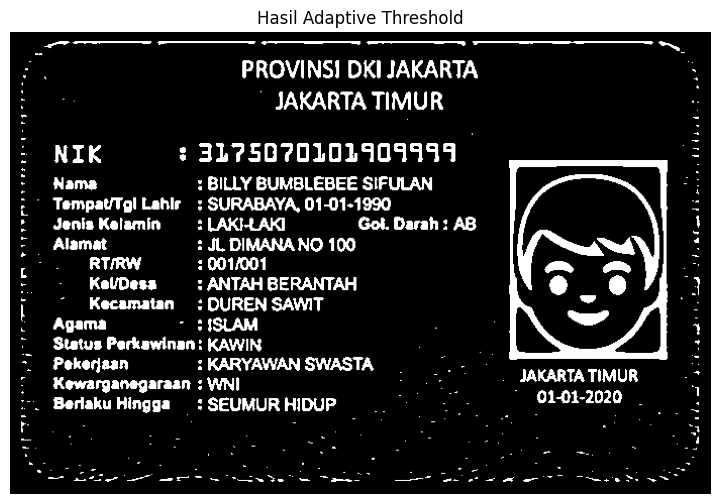

In [31]:
#Segmentasi dengan Adaptive Threshold
thresh = cv2.adaptiveThreshold(
    blur,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    31,
    10
)

plt.figure(figsize=(12, 6))
plt.imshow(thresh, cmap="gray")
plt.title("Hasil Adaptive Threshold")
plt.axis("off")
plt.show()

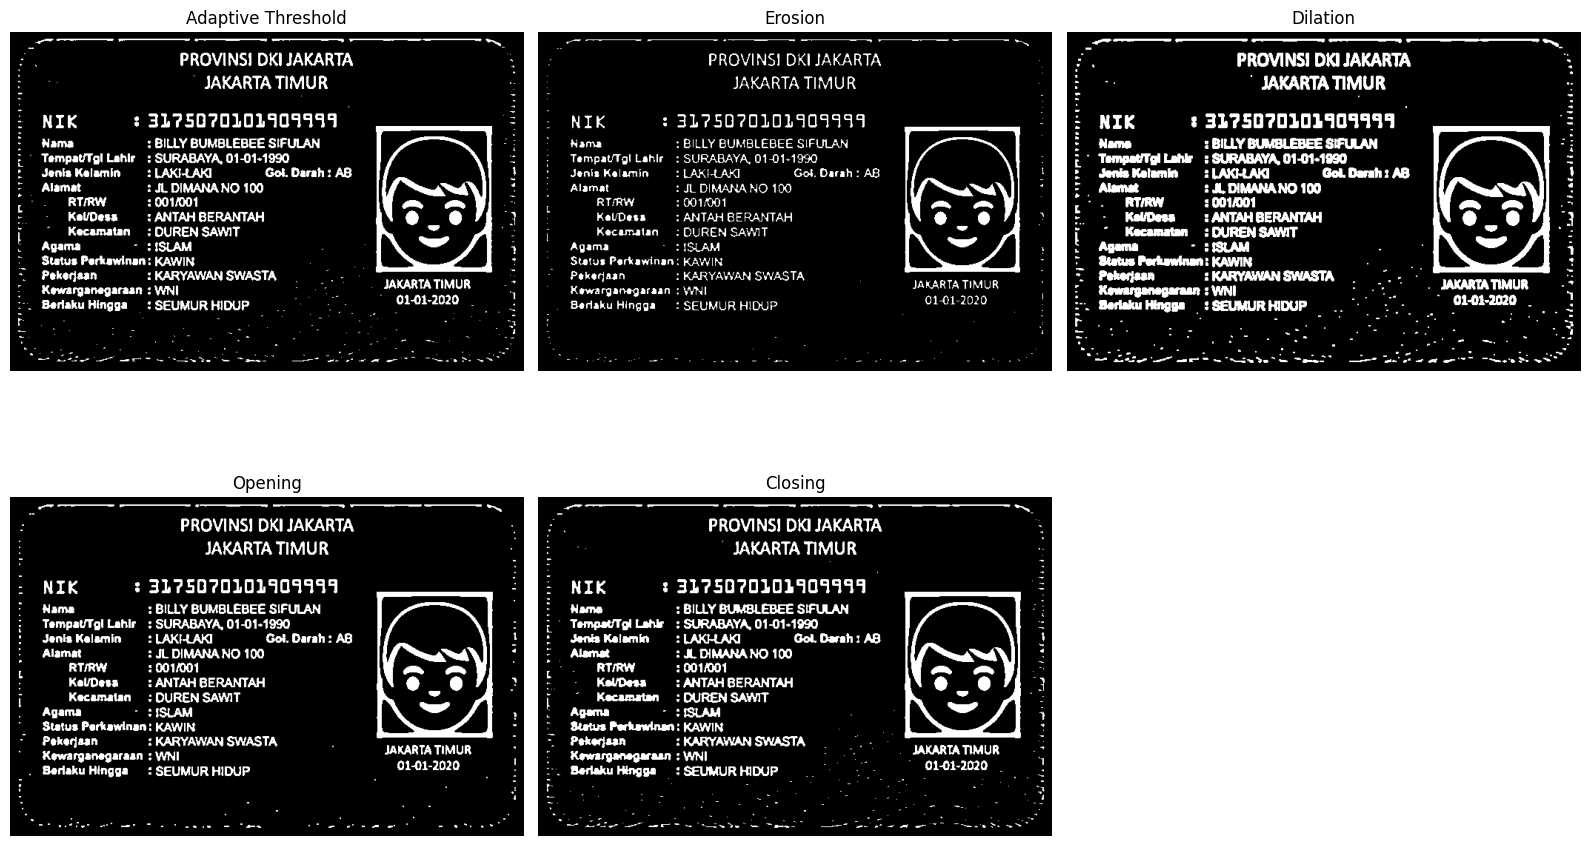

In [32]:
#Penerapan operasi morfologi
# Kernel morfologi
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))

# Operasi morfologi
erosion = cv2.erode(thresh, kernel, iterations=1)
dilation = cv2.dilate(thresh, kernel, iterations=1)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

# Menampilkan hasil
images = [thresh, erosion, dilation, opening, closing]

titles = [
    "Adaptive Threshold",
    "Erosion",
    "Dilation",
    "Opening",
    "Closing"
]

plt.figure(figsize=(16, 10))

for i, (image, title) in enumerate(zip(images, titles)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

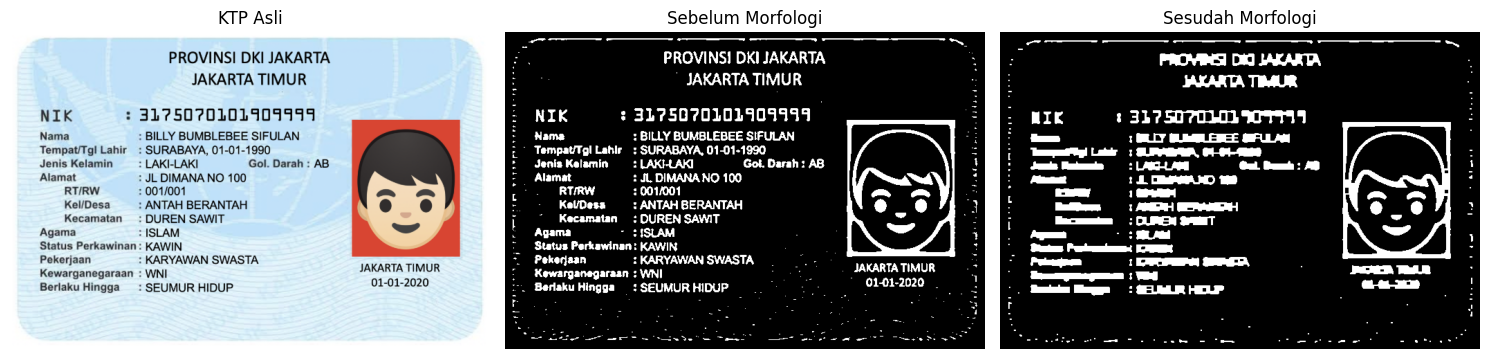

In [33]:
#Parameter untuk memperjelas tulisan

# Parameter tambahan yang dapat diuji
kernel_tambahan = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 2))

# Closing untuk menutup celah kecil pada tulisan
hasil_closing = cv2.morphologyEx(
    thresh,
    cv2.MORPH_CLOSE,
    kernel_tambahan,
    iterations=2
)

# Mengurangi noise kecil setelah closing
hasil_akhir = cv2.morphologyEx(
    hasil_closing,
    cv2.MORPH_OPEN,
    np.ones((2, 2), np.uint8),
    iterations=1
)

plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("KTP Asli")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(thresh, cmap="gray")
plt.title("Sebelum Morfologi")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(hasil_akhir, cmap="gray")
plt.title("Sesudah Morfologi")
plt.axis("off")

plt.tight_layout()
plt.show()